In [1]:
import numpy as np
import matplotlib.pyplot as plt; plt.rc('font', size=16)
import pandas as pd
from collections import Counter
import seaborn as sns

cmap = sns.color_palette("rocket_r", as_cmap=True)

In [2]:
taxa = ['B_cellulosilyticus_WH2', 
        'B_caccae', 
        'B_vulgatus', 
        'B_thetaiotaomicron', 
        'B_ovatus', 
        'R_obeum', 
        'B_uniformis', 
        'P_distasonis', 
        'C_scindens', 
        'C_aerofaciens', 
        'C_spiroforme', 
        # 'D_longicatena'
        ]

cols = ['#016bff',
        '#b91f1c',
        '#308937',
        '#ff8137',
        '#6f4fc7',
        '#d4b300',
        '#893a2b',
        '#ff6c79',
        '#16c4ff',
        '#766f41',
        '#00c800',
        '#af3261']

# pretty_names_dir = {'B_caccae': '$B. caccae$',
#                 'B_cellulosilyticus_WH2': '$B. cellulosilyticus$',
#                 'B_ovatus': '$B. ovatus$',
#                 'B_thetaiotaomicron': '$B. thetaiotaomicron$',
#                 'B_uniformis': '$B. uniformis$',
#                 'B_vulgatus': '$B. vulgatus$',
#                 'C_aerofaciens': '$C. aerofaciens$',
#                 'C_scindens': '$C. scindens$',
#                 'C_spiroforme': '$C. spiroforme$',
#                 # 'D_longicatena': '$D. longicatena$',
#                 'P_distasonis': '$P. distasonis$',
#                 'R_obeum': '$R. obeum$'}

pretty_names_dir = {'B_caccae': 'Bca',
                'B_cellulosilyticus_WH2': 'Bce',
                'B_ovatus': 'Bov',
                'B_thetaiotaomicron': 'Bth',
                'B_uniformis': 'Bun',
                'B_vulgatus': 'Bvu',
                'C_aerofaciens': 'Cae',
                'C_scindens': 'Csc',
                'C_spiroforme': 'Csp',
                # 'D_longicatena': 'Dlo',
                'P_distasonis': 'Pdi',
                'R_obeum': 'Rob'
                }

cols_species_map = dict(zip(taxa, cols))

In [3]:
def presence_absence(x):
    if pd.isna(x):
        return 0
    else:
        return 1
    
def drop_nan(x):
    if pd.isna(x):
        return False
    else:
        return True
    
def calculate_metabolic_distance(table):
    J = np.zeros([len(table.columns), len(table.columns)])
    for i in range(len(table.columns)):
        for j in range(len(table.columns)):
            if i == j:
                J[i,j] = 0
            else:
                set_rep = Counter(table.iloc[:,[i,j]].sum(axis=1))
                J[i,j] = 1 - (set_rep[2]/(set_rep[1]+set_rep[2]))
    return pd.DataFrame(J, index=table.columns, columns=table.columns)

# Whole Metabolism

 ## Metabolic Distance and Metabolic Added Information

In [4]:
ECs = []
for taxon in taxa:
    eggNOG = pd.read_table(f'eggNOG/{taxon}_eggNOG.tsv', index_col=0, skiprows=4, skipfooter=3, engine='python')
    eggNOG['Species'] = taxon
    eggNOG = eggNOG[eggNOG['EC'] != '-'].copy()
    eggNOG.set_index('EC', inplace=True)
    eggNOG = eggNOG.loc[:,['Species']].copy()
    eggNOG.reset_index(inplace=True)
    eggNOG.set_index('Species', inplace=True)
    eggNOG = eggNOG['EC'].str.split(',', expand=True)
    eggNOG.reset_index(inplace=True)
    eggNOG = eggNOG.melt(id_vars='Species', value_name='EC')
    eggNOG.drop(columns='variable', inplace=True)
    eggNOG.dropna(inplace=True)
    eggNOG.drop_duplicates(subset=['EC'], inplace=True)
    eggNOG.set_index('EC', inplace=True)
    eggNOG.columns = [eggNOG['Species'][0]]
    ECs.append(eggNOG)
ECs = pd.concat(ECs, axis=1)
ECs = ECs.applymap(presence_absence)
ECs 

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC,,,,,,,,,,,
4.3.2.1,1,1,1,1,1,1,1,1,1,1,0
2.4.2.10,1,1,1,1,1,1,1,1,1,1,1
2.1.1.297,1,1,1,1,1,1,1,1,1,1,1
1.1.1.193,1,1,1,1,1,1,1,1,0,0,0
2.5.1.31,1,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...
3.1.26.8,0,0,0,0,0,0,0,0,0,0,1
4.1.1.50,0,0,0,0,0,0,0,0,0,0,1
3.4.21.96,0,0,0,0,0,0,0,0,0,0,1


/home/acs98/.local/lib/python3.10/site-packages/seaborn/matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


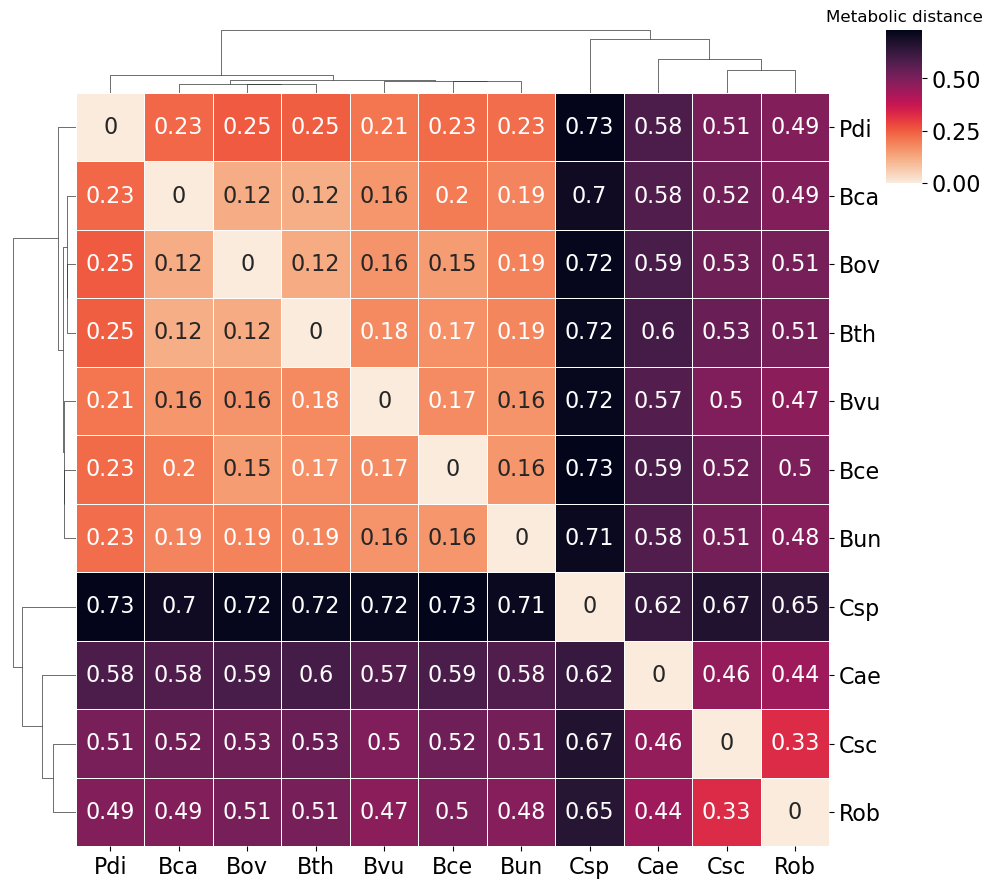

In [5]:
metdist_ECs = calculate_metabolic_distance(ECs)
metdist_ECs = metdist_ECs.sort_index(axis=0).sort_index(axis=1)
metdist_ECs.to_csv('metabolic-metrics/metdist_ECs.tsv', sep='\t', index=True, header=True)
metdist_ECs_pretty = metdist_ECs.copy()
metdist_ECs_pretty.columns = metdist_ECs_pretty.columns.map(pretty_names_dir)
metdist_ECs_pretty.index = metdist_ECs_pretty.index.map(pretty_names_dir)
ax = sns.clustermap(metdist_ECs_pretty, 
    cmap=cmap, 
    row_cluster=True, 
    col_cluster=True,
    dendrogram_ratio=(0.08, 0.08), 
    annot=True, 
    cbar_pos=(1, 0.8, 0.04, 0.17),
    yticklabels='auto',
    xticklabels='auto',
    figsize=(9, 9),
    linewidths=0.5
    )
cax = ax.ax_heatmap
cax.set_xticklabels(cax.get_xticklabels(), rotation=0, ha='center')
cax.set_yticklabels(cax.get_yticklabels(), rotation=0, ha='left')
plt.title('Metabolic distance', fontsize=12)
plt.savefig('metabolic-metrics/metdist_ECs.svg', bbox_inches='tight')
plt.show()

In [7]:
KOs = []
for taxon in taxa:
    eggNOG = pd.read_table(f'eggNOG/{taxon}_eggNOG.tsv', index_col=0, skiprows=4, skipfooter=3, engine='python')
    eggNOG['Species'] = taxon
    eggNOG = eggNOG[eggNOG['KEGG_ko'] != '-'].copy()
    eggNOG.set_index('KEGG_ko', inplace=True)
    eggNOG = eggNOG.loc[:,['Species']].copy()
    eggNOG.reset_index(inplace=True)
    eggNOG.set_index('Species', inplace=True)
    eggNOG = eggNOG['KEGG_ko'].str.split(',', expand=True)
    eggNOG.reset_index(inplace=True)
    eggNOG = eggNOG.melt(id_vars='Species', value_name='KEGG_ko')
    eggNOG.drop(columns='variable', inplace=True)
    eggNOG.dropna(inplace=True)
    eggNOG.drop_duplicates(subset=['KEGG_ko'], inplace=True)
    eggNOG['KEGG_ko'] = eggNOG['KEGG_ko'].apply(lambda x: x.replace('ko:', ''))
    eggNOG.set_index('KEGG_ko', inplace=True)
    eggNOG.columns = [eggNOG['Species'][0]]
    KOs.append(eggNOG)
KOs = pd.concat(KOs, axis=1)
KOs = KOs.applymap(presence_absence)
KOs 

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
KEGG_ko,,,,,,,,,,,
K01755,1,1,1,1,1,1,1,1,1,1,0
K00762,1,1,1,1,1,1,1,1,1,1,1
K03565,1,1,1,1,1,1,1,1,1,1,0
K02493,1,1,1,1,1,1,1,1,1,1,1
K11752,1,1,1,1,1,1,1,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
K21687,0,0,0,0,0,0,0,0,0,0,1
K07093,0,0,0,0,0,0,0,0,0,0,1
K02041,0,0,0,0,0,0,0,0,0,0,1


/home/acs98/.local/lib/python3.10/site-packages/seaborn/matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


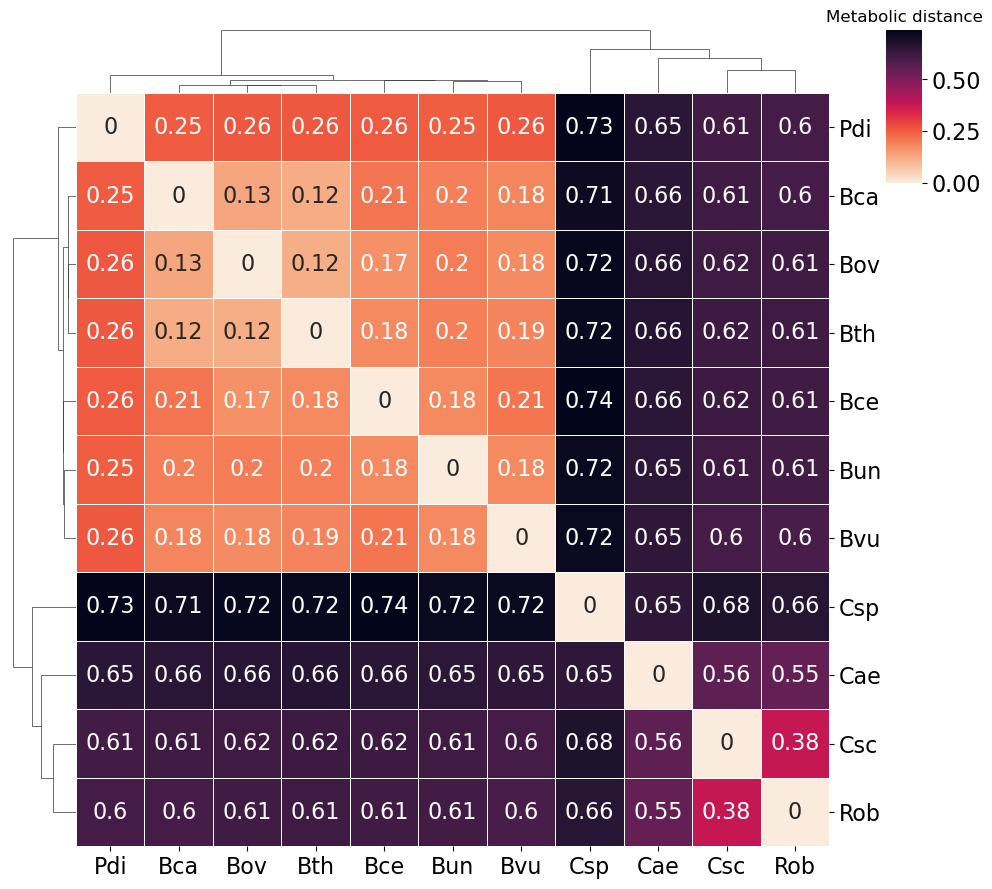

In [8]:
metdist_KOs = calculate_metabolic_distance(KOs)
metdist_KOs = metdist_KOs.sort_index(axis=0).sort_index(axis=1)
metdist_KOs.to_csv('metabolic-metrics/metdist_KOs.tsv', sep='\t', index=True, header=True)
metdist_KOs_pretty = metdist_KOs.copy()
metdist_KOs_pretty.columns = metdist_KOs_pretty.columns.map(pretty_names_dir)
metdist_KOs_pretty.index = metdist_KOs_pretty.index.map(pretty_names_dir)
ax = sns.clustermap(metdist_KOs_pretty, 
    cmap=cmap, 
    row_cluster=True, 
    col_cluster=True,
    dendrogram_ratio=(0.08, 0.08), 
    annot=True, 
    cbar_pos=(1, 0.8, 0.04, 0.17),
    yticklabels='auto',
    xticklabels='auto',
    figsize=(9, 9),
    linewidths=0.5
    )
cax = ax.ax_heatmap
cax.set_xticklabels(cax.get_xticklabels(), rotation=0, ha='center')
cax.set_yticklabels(cax.get_yticklabels(), rotation=0, ha='left')
plt.title('Metabolic distance', fontsize=12)
plt.savefig('metabolic-metrics/metdist_KOs.svg', bbox_inches='tight')
plt.show()

# Carbohydrate metabolism

## Metabolic Distance and Metabolic Added Information

In [10]:
dbCAN_sub = []
for taxon in taxa:
    cazymes = pd.read_table(f'dbCAN3/{taxon}/overview.txt', sep='\t', index_col=1)
    cazymes['Species'] = taxon
    cazymes = cazymes[cazymes['#ofTools'] >= 2].loc[:, ['Species']].copy()
    cazymes.reset_index(inplace=True)
    cazymes.set_index('Species', inplace=True)
    cazymes = cazymes['EC#'].str.split('|', expand=True)
    cazymes.reset_index(inplace=True)
    cazymes = cazymes.melt(id_vars='Species', value_name='EC#')
    cazymes.drop(columns='variable', inplace=True)
    cazymes.dropna(inplace=True)
    cazymes = cazymes[cazymes['EC#'] != '-'].copy()
    cazymes.drop_duplicates(subset=['EC#'], inplace=True)
    cazymes.set_index('EC#', inplace=True)
    cazymes.columns = [cazymes['Species'][0]]
    dbCAN_sub.append(cazymes)
dbCAN_sub = pd.concat(dbCAN_sub, axis=1)
dbCAN_sub = dbCAN_sub.applymap(presence_absence)
dbCAN_sub

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC#,,,,,,,,,,,
3.2.1.55,1,1,1,1,1,1,1,1,0,0,0
3.2.1.37,1,1,1,1,1,1,1,1,0,1,1
3.2.1.-,1,1,1,1,1,1,1,1,1,1,1
3.2.1.92,1,0,0,0,0,0,1,0,0,0,0
3.2.1.21,1,1,1,1,1,1,1,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
4.2.2.12,0,0,0,0,0,0,0,0,0,0,1
3.2.1.97,0,0,0,0,0,0,0,0,0,0,1
3.2.1.50,0,0,0,0,0,0,0,0,0,0,1


/home/acs98/.local/lib/python3.10/site-packages/seaborn/matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


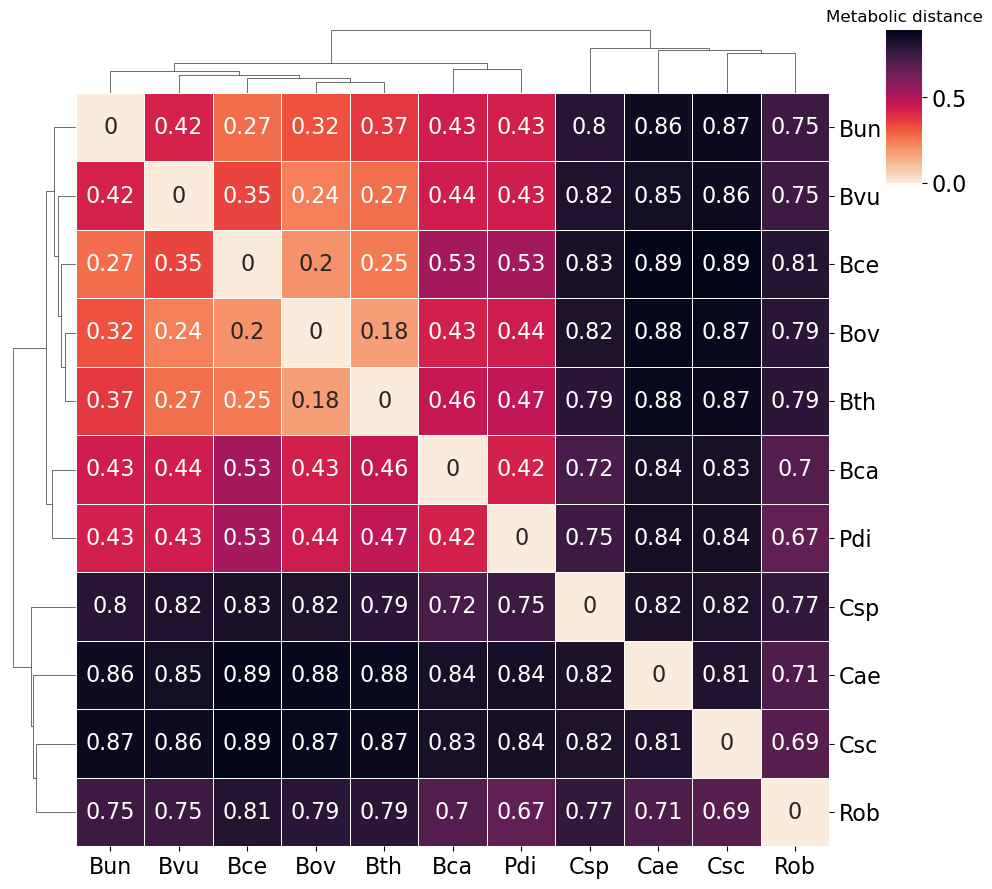

In [11]:
metdist_carbo = calculate_metabolic_distance(dbCAN_sub)
metdist_carbo = metdist_carbo.sort_index(axis=0).sort_index(axis=1)
metdist_carbo.to_csv('metabolic-metrics/metdist_carbo.tsv', sep='\t', index=True, header=True)
metdist_carbo_pretty = metdist_carbo.copy()
metdist_carbo_pretty.columns = metdist_carbo_pretty.columns.map(pretty_names_dir)
metdist_carbo_pretty.index = metdist_carbo_pretty.index.map(pretty_names_dir)
ax = sns.clustermap(metdist_carbo_pretty, 
    cmap=cmap,
    row_cluster=True, 
    col_cluster=True,
    dendrogram_ratio=(0.08, 0.08), 
    annot=True, 
    cbar_pos=(1, 0.8, 0.04, 0.17),
    yticklabels='auto',
    xticklabels='auto',
    linewidths=0.5,
    figsize=(9, 9))
cax = ax.ax_heatmap
cax.set_xticklabels(cax.get_xticklabels(), rotation=0, ha='center')
cax.set_yticklabels(cax.get_yticklabels(), rotation=0, ha='left')
plt.title('Metabolic distance', fontsize=12)
plt.savefig('metabolic-metrics/metdist_carbo.svg', bbox_inches='tight')
plt.show()

# Amino Acid Metabolism

 ## Metabolic distance and Metabolic Added Information

In [13]:
eggNOG = []
for taxon in taxa:
    aminoacid_metabolism = pd.read_table(f'eggNOG/{taxon}_eggNOG.tsv', index_col=0, skiprows=4, skipfooter=3, engine='python')
    aminoacid_metabolism['Species'] = taxon
    aminoacid_metabolism = aminoacid_metabolism[aminoacid_metabolism['COG_category'].apply(get_aminoacid_metabolism)].copy()
    aminoacid_metabolism = aminoacid_metabolism[aminoacid_metabolism['EC'] != '-'].copy()
    aminoacid_metabolism.set_index('EC', inplace=True)
    aminoacid_metabolism = aminoacid_metabolism.loc[:,['Species']].copy()
    aminoacid_metabolism.reset_index(inplace=True)
    aminoacid_metabolism.set_index('Species', inplace=True)
    aminoacid_metabolism = aminoacid_metabolism['EC'].str.split(',', expand=True)
    aminoacid_metabolism.reset_index(inplace=True)
    aminoacid_metabolism = aminoacid_metabolism.melt(id_vars='Species', value_name='EC')
    aminoacid_metabolism.drop(columns='variable', inplace=True)
    aminoacid_metabolism.dropna(inplace=True)
    aminoacid_metabolism.drop_duplicates(subset=['EC'], inplace=True)
    aminoacid_metabolism.set_index('EC', inplace=True)
    aminoacid_metabolism.columns = [aminoacid_metabolism['Species'][0]]
    eggNOG.append(aminoacid_metabolism)
eggNOG = pd.concat(eggNOG, axis=1)
eggNOG = eggNOG.applymap(presence_absence)
eggNOG 

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
EC,,,,,,,,,,,
4.3.2.1,1,1,1,1,1,1,1,1,1,1,0
2.7.2.11,1,1,1,1,1,0,1,1,0,1,1
1.2.1.41,1,1,1,1,1,1,1,1,1,1,1
2.1.3.11,1,1,1,1,1,0,1,1,0,0,0
1.2.1.11,1,1,1,1,1,0,1,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
1.1.1.399,0,0,0,0,0,0,0,0,0,1,0
2.4.2.17,0,0,0,0,0,0,0,0,0,1,0
1.1.1.41,0,0,0,0,0,0,0,0,0,1,0


/home/acs98/.local/lib/python3.10/site-packages/seaborn/matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


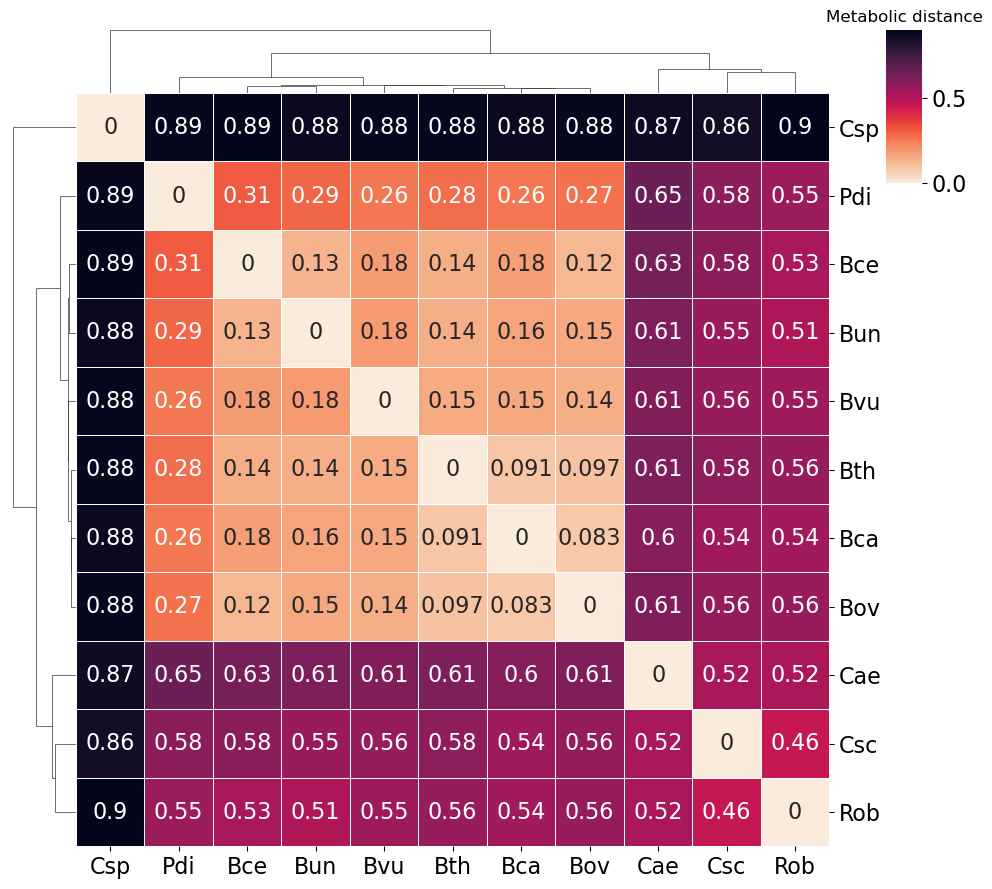

In [14]:
metdist_amino = calculate_metabolic_distance(eggNOG)
metdist_amino = metdist_amino.sort_index(axis=0).sort_index(axis=1)
metdist_amino.to_csv('metabolic-metrics/metdist_amino.tsv', sep='\t', index=True, header=True)
metdist_amino_pretty = metdist_amino.copy()
metdist_amino_pretty.columns = metdist_amino_pretty.columns.map(pretty_names_dir)
metdist_amino_pretty.index = metdist_amino_pretty.index.map(pretty_names_dir)
ax = sns.clustermap(metdist_amino_pretty, 
    cmap=cmap, 
    row_cluster=True, 
    col_cluster=True,
    dendrogram_ratio=(0.08, 0.08), 
    annot=True, 
    cbar_pos=(1, 0.8, 0.04, 0.17),
    yticklabels='auto',
    xticklabels='auto',
    figsize=(9, 9),
    linewidths=0.5,
    )
cax = ax.ax_heatmap
cax.set_xticklabels(cax.get_xticklabels(), rotation=0, ha='center')
cax.set_yticklabels(cax.get_yticklabels(), rotation=0, ha='left')
plt.title('Metabolic distance', fontsize=12)
plt.savefig('metabolic-metrics/metdist_amino.svg', bbox_inches='tight')
plt.show()

# Carbohydrate and Amino Acid Metabolism

 ## Metabolic Distance and Metabolic Added Information

In [16]:
dbCAN_sub_eggNOG = pd.concat([dbCAN_sub, eggNOG], axis=0)
dbCAN_sub_eggNOG

,B_cellulosilyticus_WH2,B_caccae,B_vulgatus,B_thetaiotaomicron,B_ovatus,R_obeum,B_uniformis,P_distasonis,C_scindens,C_aerofaciens,C_spiroforme
3.2.1.55,1,1,1,1,1,1,1,1,0,0,0
3.2.1.37,1,1,1,1,1,1,1,1,0,1,1
3.2.1.-,1,1,1,1,1,1,1,1,1,1,1
3.2.1.92,1,0,0,0,0,0,1,0,0,0,0
3.2.1.21,1,1,1,1,1,1,1,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
1.1.1.399,0,0,0,0,0,0,0,0,0,1,0
2.4.2.17,0,0,0,0,0,0,0,0,0,1,0
1.1.1.41,0,0,0,0,0,0,0,0,0,1,0
2.1.3.6,0,0,0,0,0,0,0,0,0,1,0


/home/acs98/.local/lib/python3.10/site-packages/seaborn/matrix.py:530: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


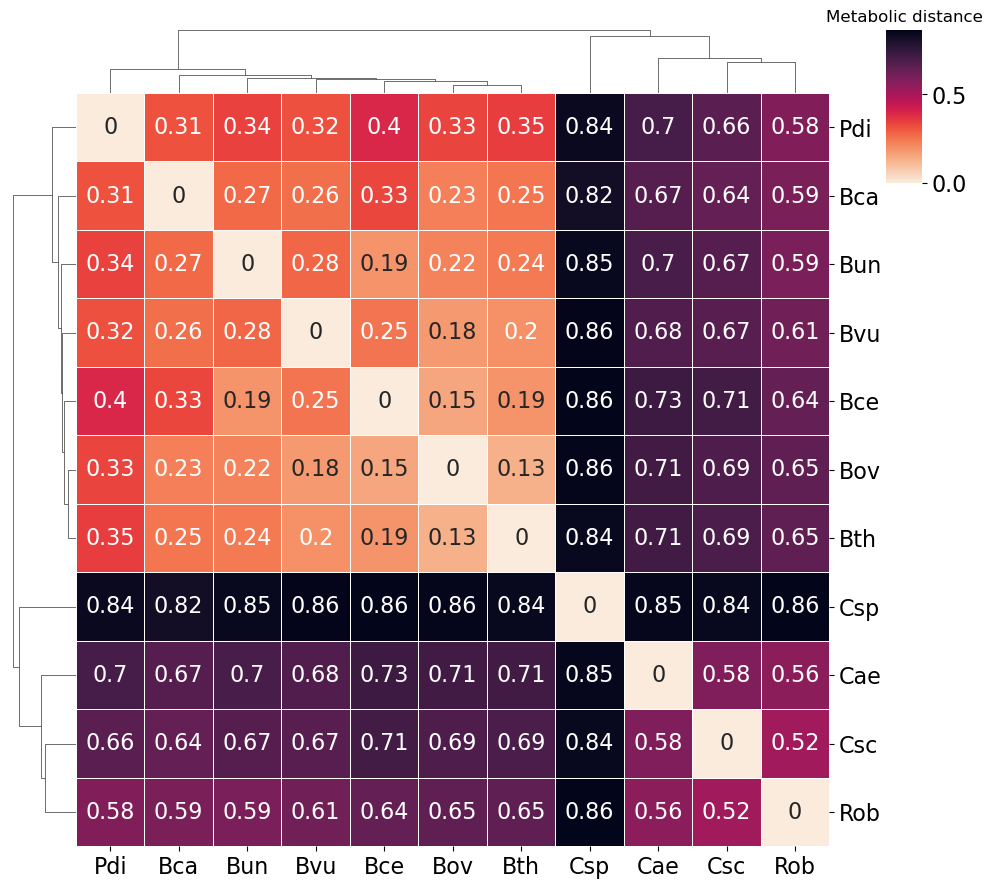

In [17]:
metdist_carbo_amino = calculate_metabolic_distance(dbCAN_sub_eggNOG)
metdist_carbo_amino = metdist_carbo_amino.sort_index(axis=0).sort_index(axis=1)
metdist_carbo_amino.to_csv('metabolic-metrics/metdist_carbo_amino.tsv', sep='\t', index=True, header=True)
metdist_carbo_amino_pretty = metdist_carbo_amino.copy()
metdist_carbo_amino_pretty.columns = metdist_carbo_amino_pretty.columns.map(pretty_names_dir)
metdist_carbo_amino_pretty.index = metdist_carbo_amino_pretty.index.map(pretty_names_dir)
ax = sns.clustermap(metdist_carbo_amino_pretty, 
    cmap=cmap, 
    row_cluster=True, 
    col_cluster=True,
    dendrogram_ratio=(0.08, 0.08), 
    annot=True, 
    cbar_pos=(1, 0.8, 0.04, 0.17),
    yticklabels='auto',
    xticklabels='auto',
    figsize=(9, 9),
    linewidths=0.5
    )
cax = ax.ax_heatmap
cax.set_xticklabels(cax.get_xticklabels(), rotation=0, ha='center')
cax.set_yticklabels(cax.get_yticklabels(), rotation=0, ha='left')
plt.title('Metabolic distance', fontsize=12)
plt.savefig('metabolic-metrics/metdist_carbo_amino.svg', bbox_inches='tight')
plt.show()